# ----------------------
# 0) Install dependencies.   لازم برای تمام اجراها
# ----------------------

In [ ]:

!pip install numpy pandas PyEMD PyWavelets scikit-learn matplotlib tensorflow keras deap --quiet


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.2/87.2 kB 5.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.0/136.0 kB 9.5 MB/s eta 0:00:00


In [ ]:
!pip install EMD-signal


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.8/76.8 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.3/82.3 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.7/119.7 kB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 150.3/150.3 kB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.8/56.8 kB 4.7 MB/s eta 0:00:00
  Attempting uninstall: dill
    Found existing installation: dill 0.3.8
    Uninstalling dill-0.3.8:
      Successfully uninstalled dill-0.3.8
  Attempting uninstall: multiprocess
    Found existing installation: multiprocess 0.70.16
    Uninstalling multiprocess-0.70.16:
      Successfully uninstalled multiprocess-0.70.16
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.0.0 requires dill<0.3.9,>=0.3.0, but you have dill 0.4.0 which is incompatible.
datasets 4.0

In [ ]:
from PyEMD import EMD

In [ ]:
!pip install --quiet tensorflow PyEMD pyswarms scikit-learn pandas matplotlib seaborn statsmodels


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.1/104.1 kB 6.4 MB/s eta 0:00:00


In [ ]:
!pip uninstall -y PyWavelets
!pip install PyWavelets


Found existing installation: PyWavelets 1.9.0
Uninstalling PyWavelets-1.9.0:
  Successfully uninstalled PyWavelets-1.9.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 61.8 MB/s eta 0:00:00


In [ ]:
!pip install --upgrade PyWavelets


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# ----------------------
# 1) transfer learning.   مدل روی ۳ دیتاست متفاوت
# ----------------------


# ontario_electricity_demand.csv

# داده دانلود شود.

# داده داخل درایو گذاشته شود.



# اگر وزنی روی دیتاستی از قبل سیو شده باشد از ان استفاده میشود. وگرنه کامل رو دیتاست ترین میشود و وزنا سیو میشود.


# وزنا داخل پوشه زیر سیو میشود:

# پوشه ای با نام زیر داخل گوگل درایو بسازید.

**demans**


In [ ]:
import os
import numpy as np
import pandas as pd
from datetime import datetime
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import pywt
from PyEMD import EMD
import pyswarms as ps
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import regularizers


FN = '/content/drive/MyDrive/ontario_electricity_demand.csv'

WINDOW = 24
HIST = 72   # بجای 168
HORIZON = 12  # بجای 24
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

# ذخیره/بارگذاری وزن‌ها
PRETRAINED_ENCODER_PATH = '/content/drive/MyDrive/demans/encoder_weights.weights.h5'  # اگر داری بارگذاری می‌شود
SAVE_ENCODER_PATH = '/content/drive/MyDrive/demans/encoder_weights.weights.h5'        # ذخیره نهایی encoder
BEST_MODEL_PATH = '/content/drive/MyDrive/demans/best_model.h5'                      # فرمت HDF5 برای parity با نتایج قبلی

# Two-stage training
TWO_STAGE = True
# Stage A:
STAGE_A_EPOCHS = 3
STAGE_A_LR = 5e-4
# Stage B: fine-tune
STAGE_B_EPOCHS = 15
FINETUNE_LR = 2.5e-4
FINETUNE_UNFREEZE_LAST_N = 9999  # اگر بزرگ (>= تعداد لایه‌ها) => full unfreeze


USE_PRETRAINED_ENCODER = os.path.exists(PRETRAINED_ENCODER_PATH)

# Mixed precision (GPU)
USE_MIXED_PRECISION = False
if USE_MIXED_PRECISION:
    from tensorflow.keras.mixed_precision import experimental as mixed_precision
    policy = mixed_precision.Policy('mixed_float16')
    mixed_precision.set_policy(policy)
    print('Mixed precision enabled:', policy)

# Callbacks / optimizer
BATCH = 8  # بجای 32

EARLY_STOP_PATIENCE = 12
CLIPNORM = 1.0
HUBER_DELTA = 0.5


In [ ]:

# --------------------  Positional / Transformer --------------------

def PositionalEncodingLayer(maxlen, d_model):
    inp = keras.Input((maxlen, d_model))
    pos_emb = layers.Embedding(input_dim=maxlen, output_dim=d_model)(tf.range(start=0, limit=maxlen))
    x = inp + pos_emb
    return keras.Model(inputs=inp, outputs=x, name='pos_enc')


def transformer_encoder_block(x, head_size, num_heads, ff_dim, dropout=0.1):
    x1 = layers.LayerNormalization(epsilon=1e-6)(x)
    attn = layers.MultiHeadAttention(key_dim=head_size, num_heads=num_heads, dropout=dropout)(x1, x1)
    attn = layers.Dropout(dropout)(attn)
    x2 = layers.Add()([attn, x])
    x3 = layers.LayerNormalization(epsilon=1e-6)(x2)
    x3 = layers.Dense(ff_dim, activation='relu', kernel_regularizer=regularizers.l2(1e-5))(x3)
    x3 = layers.Dropout(dropout)(x3)
    x3 = layers.Dense(x.shape[-1], kernel_regularizer=regularizers.l2(1e-5))(x3)
    out = layers.Add()([x3, x2])
    return out

# -------------------- 1) Load & preprocess --------------------
if not os.path.exists(FN):
    raise FileNotFoundError(f"Upload your dataset and set 'FN'. Tried: {FN}")
print('Loading', FN)
_df = pd.read_csv(FN)
_df = _df.rename(columns={c: c.strip() for c in _df.columns})
if 'date' in _df.columns:
    _df['date'] = pd.to_datetime(_df['date'], errors='coerce')
elif 'datetime' in _df.columns:
    _df['date'] = pd.to_datetime(_df['datetime'], errors='coerce')
else:
    _df['date'] = pd.to_datetime(_df.iloc[:,0], errors='coerce')

if 'hour' in _df.columns:
    try:
        _df['hour'] = _df['hour'].astype(int)
    except:
        pass

if 'date' in _df.columns and 'hour' in _df.columns:
    _df['timestamp'] = _df.apply(lambda r: pd.Timestamp(r['date']) + pd.Timedelta(int(r['hour'])-1, unit='h'), axis=1)
else:
    if 'timestamp' not in _df.columns:
        _df['timestamp'] = pd.to_datetime(_df['date'], errors='coerce')

_df = _df.sort_values('timestamp').reset_index(drop=True)

if 'hourly_demand' not in _df.columns:
    candidates = [c for c in _df.columns if 'demand' in c.lower()]
    if len(candidates)>0:
        _df = _df.rename(columns={candidates[0]:'hourly_demand'})
    else:
        raise ValueError("No hourly_demand column found. Rename demand column to 'hourly_demand'.")

series = _df[['timestamp','hourly_demand']].copy().dropna().reset_index(drop=True)
series['value'] = series['hourly_demand'].astype(float)

# 2) Denoise EMD + DWT
print('Running EMD decomposition... (this step can be slow)')
emd = EMD()
s = series['value'].values
imfs = emd.emd(s)
if imfs.ndim == 1:
    imfs = imfs[np.newaxis, :]
print('IMFs shape:', imfs.shape)

denoised = np.sum(imfs[1:], axis=0) if imfs.shape[0] > 1 else s.copy()
coeffs = pywt.wavedec(denoised, 'db4', level=4)
approx = pywt.upcoef('a', coeffs[0], 'db4', level=4, take=len(denoised))
d1 = pywt.upcoef('d', coeffs[1], 'db4', level=4, take=len(denoised))
d2 = pywt.upcoef('d', coeffs[2], 'db4', level=3, take=len(denoised))

feat_df = pd.DataFrame({
    'timestamp': series['timestamp'],
    'demand': s,
    'denoised': denoised,
    'dwt_a': approx,
    'dwt_d1': d1,
    'dwt_d2': d2
})

# 3) PSO K selection
X = []
for i in range(WINDOW, len(feat_df)):
    window = feat_df['denoised'].values[i-WINDOW:i]
    X.append(window)
X = np.array(X)
if len(X) < 10:
    best_k = 3
else:
    pca = PCA(n_components=min(8, X.shape[1]))
    Xr = pca.fit_transform(X)
    def pso_objective(k_candidates):
        n_particles = k_candidates.shape[0]
        scores = []
        for i in range(n_particles):
            k = int(np.clip(np.round(k_candidates[i,0]), 2, 10))
            kmeans = KMeans(n_clusters=k, random_state=RANDOM_SEED).fit(Xr)
            scores.append(kmeans.inertia_)
        return np.array(scores)
    options = {'c1': 0.5, 'c2': 0.3, 'w': 0.9}
    bounds = (np.array([2.0]), np.array([10.0]))
    optimizer = ps.single.GlobalBestPSO(n_particles=12, dimensions=1, options=options, bounds=bounds)
    best_cost, best_pos = optimizer.optimize(pso_objective, iters=30, verbose=False)
    best_k = int(np.clip(np.round(best_pos[0]), 2, 10))
print('PSO-chosen k:', best_k)

if len(X) >= 2:
    kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_SEED).fit(pca.transform(X))
    labels = kmeans.labels_
    cluster_series = np.concatenate([np.full(WINDOW, -1), labels])
else:
    cluster_series = np.full(len(feat_df), -1)
feat_df['cluster'] = cluster_series.astype(int)

# 4) features
feat_df['hour'] = feat_df['timestamp'].dt.hour
feat_df['dow'] = feat_df['timestamp'].dt.weekday
feat_df['hour_sin'] = np.sin(2*np.pi*feat_df['hour']/24)
feat_df['hour_cos'] = np.cos(2*np.pi*feat_df['hour']/24)
feat_df['dow_sin'] = np.sin(2*np.pi*feat_df['dow']/7)
feat_df['dow_cos'] = np.cos(2*np.pi*feat_df['dow']/7)
for lag in [1,2,3,24,168]:
    feat_df[f'lag_{lag}'] = feat_df['denoised'].shift(lag)
for win in [3,24,168]:
    feat_df[f'roll_mean_{win}'] = feat_df['denoised'].rolling(window=win, min_periods=1).mean()
    feat_df[f'roll_std_{win}'] = feat_df['denoised'].rolling(window=win, min_periods=1).std().fillna(0)
feat_df = feat_df.dropna().reset_index(drop=True)

# 5) scale
num_cols = ['demand','denoised','dwt_a','dwt_d1','dwt_d2',
            'lag_1','lag_2','lag_3','lag_24','lag_168',
            'roll_mean_3','roll_mean_24','roll_mean_168',
            'roll_std_3','roll_std_24','roll_std_168']
num_cols = [c for c in num_cols if c in feat_df.columns]
scaler = MinMaxScaler()
feat_df[num_cols] = scaler.fit_transform(feat_df[num_cols])
scaler_y = MinMaxScaler()
feat_df['demand_scaled'] = scaler_y.fit_transform(feat_df[['demand']])
features = ['demand_scaled','denoised','dwt_a','dwt_d1','dwt_d2',
            'hour_sin','hour_cos','dow_sin','dow_cos','cluster'] + [c for c in feat_df.columns if c.startswith('lag_') or c.startswith('roll_')]
features = [f for f in features if f in feat_df.columns]

# 6) supervised samples
feat_np = feat_df[features].to_numpy(dtype=np.float32)
demand_np = feat_df['demand'].to_numpy(dtype=np.float32)
X_samples = []
y_samples = []
for i in range(HIST, len(feat_np) - HORIZON + 1):
    X_samples.append(feat_np[i-HIST:i])
    y_samples.append(demand_np[i:i+HORIZON])
X_samples = np.array(X_samples, dtype=np.float32)
y_samples = np.array(y_samples, dtype=np.float32)
print("X_samples shape:", X_samples.shape, "y_samples shape:", y_samples.shape)
y_scaled = scaler_y.transform(y_samples.reshape(-1,1)).reshape(y_samples.shape).astype(np.float32)
# split
split_idx = int(0.8 * len(X_samples))
X_train, X_test = X_samples[:split_idx], X_samples[split_idx:]
y_train, y_test = y_scaled[:split_idx], y_scaled[split_idx:]
val_idx = int(0.9 * len(X_train))
X_tr, X_val = X_train[:val_idx], X_train[val_idx:]
y_tr, y_val = y_train[:val_idx], y_train[val_idx:]
print("Train / Val / Test sizes:", X_tr.shape[0], X_val.shape[0], X_test.shape[0])

# 7) build encoder + head (exact architecture)
d_model = 128
input_feats = X_tr.shape[-1]
encoder_input = keras.Input(shape=(HIST, input_feats), name='encoder_input')
xx = layers.GaussianNoise(1e-3)(encoder_input)
xx = layers.Conv1D(filters=64, kernel_size=3, padding='causal', activation='relu', name='conv1')(xx)
xx = layers.Conv1D(filters=d_model, kernel_size=3, padding='causal', activation='relu', name='conv2')(xx)
xx = layers.Dense(d_model, name='proj')(xx)
pos_layer = PositionalEncodingLayer(HIST, d_model)
xx = pos_layer(xx)
for _ in range(2):  # بجای 4
    xx = transformer_encoder_block(xx, head_size=32, num_heads=2, ff_dim=128, dropout=0.1)


encoder_seq_out = xx
encoder_pooled = layers.GlobalAveragePooling1D(name='encoder_pool')(encoder_seq_out)
encoder_out = layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(1e-5), name='encoder_dense')(encoder_pooled)
encoder_model = keras.Model(encoder_input, encoder_out, name='encoder')
# head
head_input = keras.Input(shape=(256,), name='head_input')
h = layers.Dropout(0.25)(head_input)
h = layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(1e-5))(h)
head_output = layers.Dense(HORIZON, activation='linear', kernel_regularizer=regularizers.l2(1e-5))(h)
head_model = keras.Model(head_input, head_output, name='head')
# full
model_input = encoder_input
model_output = head_model(encoder_model(model_input))
model = keras.Model(model_input, model_output, name='full_model')

# helper: set encoder trainable last N non-input layers
def set_encoder_trainable(encoder, unfreeze_last_n=0):
    layers_list = [ly for ly in encoder.layers if not isinstance(ly, keras.layers.InputLayer)]
    if unfreeze_last_n <= 0:
        for ly in layers_list:
            ly.trainable = False
        return
    for ly in layers_list:
        ly.trainable = False
    count = 0
    for ly in reversed(layers_list):
        ly.trainable = True
        count += 1
        if count >= unfreeze_last_n:
            break

# Load pretrained encoder if exists (transfer)
if USE_PRETRAINED_ENCODER:
    try:
        encoder_model.load_weights(PRETRAINED_ENCODER_PATH)
        print('Loaded pretrained encoder weights from', PRETRAINED_ENCODER_PATH)
    except Exception as e:
        print('Could not load pretrained encoder:', e)

# 8) callbacks
checkpoint_path = BEST_MODEL_PATH
callbacks = [
    keras.callbacks.ModelCheckpoint(checkpoint_path, monitor='val_loss', save_best_only=True, verbose=1),
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=EARLY_STOP_PATIENCE, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, verbose=1)
]


Loading /content/drive/MyDrive/ontario_electricity_demand.csv
Running EMD decomposition... (this step can be slow)


2025-12-15 14:26:15,884 - PyEMD.EMD - INFO - Max iterations reached for IMF. Continuing with another IMF.


IMFs shape: (15, 183432)
PSO-chosen k: 10
X_samples shape: (183181, 72, 21) y_samples shape: (183181, 12)
Train / Val / Test sizes: 131889 14655 36637


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


In [ ]:
# ---------------- 9) TWO-STAGE pipeline ----------------
# Stage A: freeze encoder, train head only for few epochs (warm head without overfitting)
# Stage B: unfreeze (last-N or full) and fine-tune with lower LR and ReduceLROnPlateau

if TWO_STAGE:
    # Stage A
    print("\n== STAGE A: Train head with encoder frozen ==")
    set_encoder_trainable(encoder_model, unfreeze_last_n=0)
    opt_a = keras.optimizers.Adam(learning_rate=STAGE_A_LR, clipnorm=CLIPNORM)
    model.compile(optimizer=opt_a, loss=keras.losses.Huber(delta=HUBER_DELTA), metrics=[keras.metrics.MeanAbsoluteError()])
    if STAGE_A_EPOCHS > 0:
        history_a = model.fit(
            X_tr, y_tr,
            validation_data=(X_val, y_val),
            epochs=STAGE_A_EPOCHS,
            batch_size=BATCH,
            callbacks=callbacks,
            verbose=2
        )
    else:
        print("Skipping Stage A (STAGE_A_EPOCHS <= 0)")

    # reload best after Stage A
    if os.path.exists(checkpoint_path):
        try:
            model.load_weights(checkpoint_path)
            print("Loaded best Stage A model weights")
        except Exception as e:
            print("Could not load best Stage A weights:", e)

    # Stage B: fine-tune
    print("\n== STAGE B: Fine-tune encoder ==")
    # decide how many to unfreeze: if FINETUNE_UNFREEZE_LAST_N is very large -> full unfreeze
    if FINETUNE_UNFREEZE_LAST_N >= 9999:
        # full unfreeze
        for ly in encoder_model.layers:
            if not isinstance(ly, keras.layers.InputLayer):
                ly.trainable = True
    else:
        set_encoder_trainable(encoder_model, unfreeze_last_n=FINETUNE_UNFREEZE_LAST_N)

    # compile with lower LR (but not too small) and optionally warmup via lower LR then ReduceLROnPlateau
    opt_b = keras.optimizers.Adam(learning_rate=FINETUNE_LR, clipnorm=CLIPNORM)
    model.compile(optimizer=opt_b, loss=keras.losses.Huber(delta=HUBER_DELTA), metrics=[keras.metrics.MeanAbsoluteError()])
    if STAGE_B_EPOCHS > 0:
        history_b = model.fit(
            X_tr, y_tr,
            validation_data=(X_val, y_val),
            epochs=STAGE_B_EPOCHS,
            batch_size=BATCH,
            callbacks=callbacks,
            verbose=2
        )
    else:
        print("Skipping Stage B (STAGE_B_EPOCHS <= 0)")

else:
    # Single-stage (preserve original behaviour)
    print("\n== Single-stage (train full model) ==")
    for ly in encoder_model.layers:
        if not isinstance(ly, keras.layers.InputLayer):
            ly.trainable = True
    opt = keras.optimizers.Adam(learning_rate=STAGE_A_LR, clipnorm=CLIPNORM)
    model.compile(optimizer=opt, loss=keras.losses.Huber(delta=HUBER_DELTA), metrics=[keras.metrics.MeanAbsoluteError()])
    history = model.fit(
        X_tr, y_tr,
        validation_data=(X_val, y_val),
        epochs=STAGE_B_EPOCHS,
        batch_size=BATCH,
        callbacks=callbacks,
        verbose=2
    )

# after training: save encoder weights once and ensure best full-model loaded
if os.path.exists(checkpoint_path):
    try:
        model.load_weights(checkpoint_path)
        print("Loaded final best full-model weights:", checkpoint_path)
    except Exception as e:
        print("Could not load final best weights:", e)

try:
    encoder_model.save_weights(SAVE_ENCODER_PATH, overwrite=True)
    print("Encoder weights saved ONCE at end:", SAVE_ENCODER_PATH)
except Exception as e:
    print("Error saving encoder weights:", e)



== STAGE A: Train head with encoder frozen ==
Epoch 1/3

Epoch 1: val_loss improved from inf to 0.00334, saving model to /content/drive/MyDrive/demans/best_model.h5


2025-12-15 14:32:37,822 - absl - WARNING - You are saving your model as an HDF5 file via `model.save()` or `keras.saving.save_model(model)`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')` or `keras.saving.save_model(model, 'my_model.keras')`. 


16487/16487 - 88s - 5ms/step - loss: 0.0053 - mean_absolute_error: 0.0780 - val_loss: 0.0033 - val_mean_absolute_error: 0.0646 - learning_rate: 5.0000e-04
Epoch 2/3

Epoch 2: val_loss did not improve from 0.00334
16487/16487 - 69s - 4ms/step - loss: 0.0042 - mean_absolute_error: 0.0730 - val_loss: 0.0035 - val_mean_absolute_error: 0.0658 - learning_rate: 5.0000e-04
Epoch 3/3

Epoch 3: val_loss did not improve from 0.00334
16487/16487 - 52s - 3ms/step - loss: 0.0040 - mean_absolute_error: 0.0721 - val_loss: 0.0034 - val_mean_absolute_error: 0.0649 - learning_rate: 5.0000e-04
Restoring model weights from the end of the best epoch: 1.
Loaded best Stage A model weights

== STAGE B: Fine-tune encoder ==
Epoch 1/15

Epoch 1: val_loss improved from 0.00334 to 0.00045, saving model to /content/drive/MyDrive/demans/best_model.h5


2025-12-15 14:36:37,407 - absl - WARNING - You are saving your model as an HDF5 file via `model.save()` or `keras.saving.save_model(model)`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')` or `keras.saving.save_model(model, 'my_model.keras')`. 


16487/16487 - 116s - 7ms/step - loss: 0.0022 - mean_absolute_error: 0.0303 - val_loss: 4.5084e-04 - val_mean_absolute_error: 0.0212 - learning_rate: 2.5000e-04
Epoch 2/15

Epoch 2: val_loss improved from 0.00045 to 0.00029, saving model to /content/drive/MyDrive/demans/best_model.h5


2025-12-15 14:37:59,940 - absl - WARNING - You are saving your model as an HDF5 file via `model.save()` or `keras.saving.save_model(model)`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')` or `keras.saving.save_model(model, 'my_model.keras')`. 


... (15 outputs left out)

2025-12-15 14:53:58,939 - absl - WARNING - You are saving your model as an HDF5 file via `model.save()` or `keras.saving.save_model(model)`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')` or `keras.saving.save_model(model, 'my_model.keras')`. 


16487/16487 - 81s - 5ms/step - loss: 1.3127e-04 - mean_absolute_error: 0.0111 - val_loss: 1.0356e-04 - val_mean_absolute_error: 0.0098 - learning_rate: 1.2500e-04
Epoch 14/15

Epoch 14: val_loss did not improve from 0.00010

Epoch 14: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.
16487/16487 - 81s - 5ms/step - loss: 1.2870e-04 - mean_absolute_error: 0.0110 - val_loss: 1.1101e-04 - val_mean_absolute_error: 0.0104 - learning_rate: 1.2500e-04
Epoch 15/15

Epoch 15: val_loss improved from 0.00010 to 0.00009, saving model to /content/drive/MyDrive/demans/best_model.h5


2025-12-15 14:56:42,782 - absl - WARNING - You are saving your model as an HDF5 file via `model.save()` or `keras.saving.save_model(model)`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')` or `keras.saving.save_model(model, 'my_model.keras')`. 


16487/16487 - 83s - 5ms/step - loss: 1.1494e-04 - mean_absolute_error: 0.0103 - val_loss: 9.1882e-05 - val_mean_absolute_error: 0.0092 - learning_rate: 6.2500e-05
Restoring model weights from the end of the best epoch: 15.
Loaded final best full-model weights: /content/drive/MyDrive/demans/best_model.h5
Encoder weights saved ONCE at end: /content/drive/MyDrive/demans/encoder_weights.weights.h5


In [ ]:
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)


X_test shape: (36615, 168, 21)
y_test shape: (36615, 24)


In [ ]:
# ---------------- 10) Predict & metrics ----------------
pred_scaled = model.predict(X_test)
pred_flat = scaler_y.inverse_transform(pred_scaled.reshape(-1,1)).reshape(pred_scaled.shape)
true_flat = scaler_y.inverse_transform(y_test.reshape(-1,1)).reshape(y_test.shape)

mse = mean_squared_error(true_flat.flatten(), pred_flat.flatten())
rmse = np.sqrt(mse)
mae = mean_absolute_error(true_flat.flatten(), pred_flat.flatten())
r2 = r2_score(true_flat.flatten(), pred_flat.flatten())
print(f'Global MSE: {mse:.6f}, RMSE: {rmse:.6f}, MAE: {mae:.6f}, R2: {r2:.6f}')


1145/1145 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step
Global MSE: 0.000178, RMSE: 0.013348, MAE: 0.010233, R2: 0.979997


In [ ]:

mae_per_h = np.mean(np.abs(true_flat - pred_flat), axis=0)
rmse_per_h = np.sqrt(np.mean((true_flat - pred_flat)**2, axis=0))
for h in range(HORIZON):
    print(f'h={h+1:02d}: MAE={mae_per_h[h]:.6f}, RMSE={rmse_per_h[h]:.6f}')

mean_demand = np.mean(true_flat)
print(f'Mean demand: {mean_demand:.6f}, MAE% of mean demand: {mae/(mean_demand+1e-9)*100:.4f}%')


h=01: MAE=0.010863, RMSE=0.013717
h=02: MAE=0.009931, RMSE=0.012570
h=03: MAE=0.009543, RMSE=0.012144
h=04: MAE=0.009191, RMSE=0.011756
h=05: MAE=0.008973, RMSE=0.011520
h=06: MAE=0.008994, RMSE=0.011594
h=07: MAE=0.009255, RMSE=0.012003
h=08: MAE=0.009557, RMSE=0.012498
h=09: MAE=0.009979, RMSE=0.013035
h=10: MAE=0.010806, RMSE=0.014095
h=11: MAE=0.011943, RMSE=0.015618
h=12: MAE=0.013754, RMSE=0.018059
Mean demand: 0.530831, MAE% of mean demand: 1.9276%


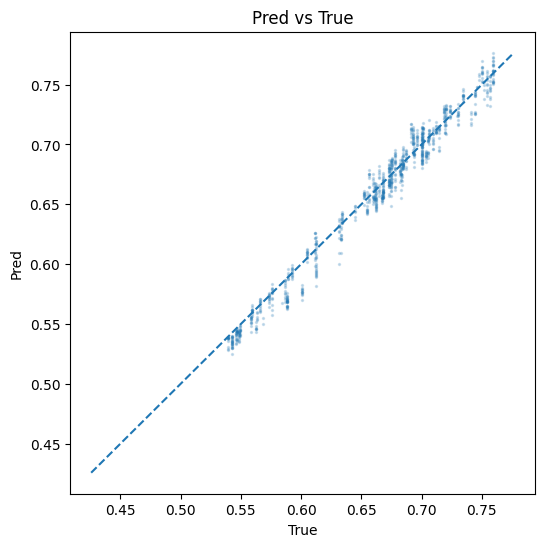

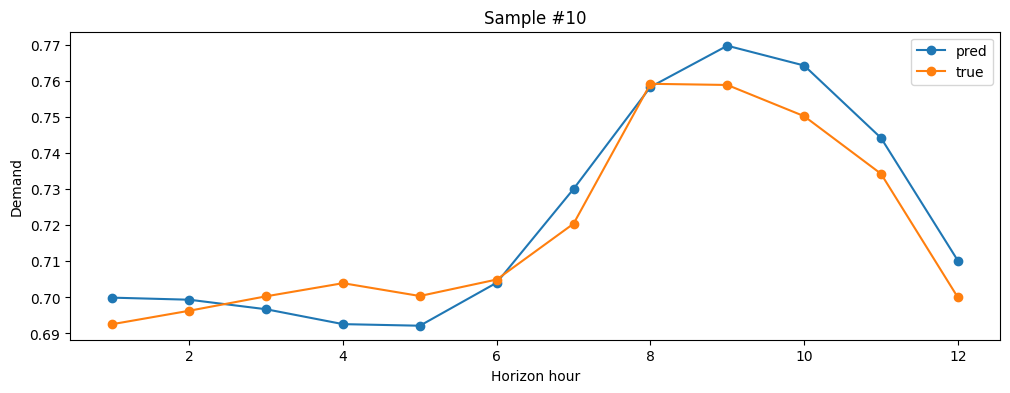

Done.


In [ ]:
# plots
import matplotlib.pyplot as plt
plt.figure(figsize=(6,6))
plt.scatter(true_flat.flatten()[:1000], pred_flat.flatten()[:1000], alpha=0.2, s=2)
lims = [min(true_flat[:1000].min(), pred_flat[:1000].min()), max(true_flat[:1000].max(), pred_flat[:1000].max())]
plt.plot(lims, lims, '--')
plt.xlabel('True'); plt.ylabel('Pred'); plt.title('Pred vs True'); plt.show()

sample_idx = min(10, pred_flat.shape[0]-1)
plt.figure(figsize=(12,4))
plt.plot(range(1,HORIZON+1), pred_flat[sample_idx], marker='o', label='pred')
plt.plot(range(1,HORIZON+1), true_flat[sample_idx], marker='o', label='true')
plt.legend(); plt.xlabel('Horizon hour'); plt.ylabel('Demand'); plt.title(f'Sample #{sample_idx}'); plt.show()

print('Done.')

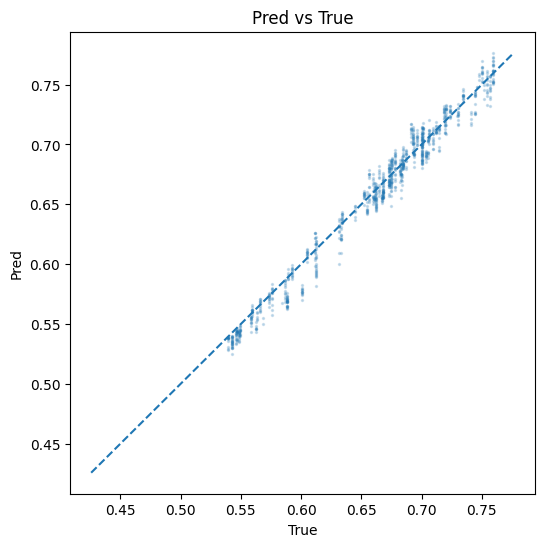

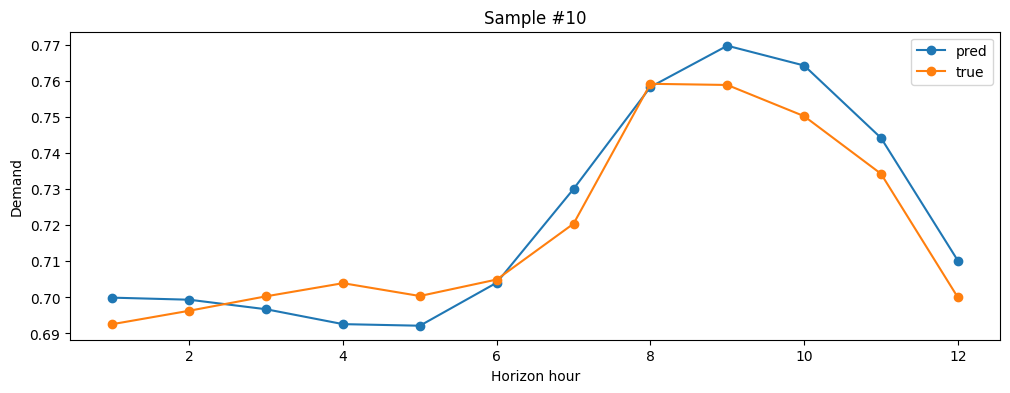

Done.


In [ ]:
# plots
import matplotlib.pyplot as plt
plt.figure(figsize=(6,6))
plt.scatter(true_flat.flatten()[:1000], pred_flat.flatten()[:1000], alpha=0.2, s=2)
lims = [min(true_flat[:1000].min(), pred_flat[:1000].min()), max(true_flat[:1000].max(), pred_flat[:1000].max())]
plt.plot(lims, lims, '--')
plt.xlabel('True'); plt.ylabel('Pred'); plt.title('Pred vs True'); plt.show()

sample_idx = min(10, pred_flat.shape[0]-1)
plt.figure(figsize=(12,4))
plt.plot(range(1,HORIZON+1), pred_flat[sample_idx], marker='o', label='pred')
plt.plot(range(1,HORIZON+1), true_flat[sample_idx], marker='o', label='true')
plt.legend(); plt.xlabel('Horizon hour'); plt.ylabel('Demand'); plt.title(f'Sample #{sample_idx}'); plt.show()

print('Done.')

# ninja_pv_wind_profiles_singleindex.csv

لینک داده:
https://data.open-power-system-data.org/ninja_pv_wind_profiles/



داده داخل درایو گذاشته شود



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!head /content/drive/MyDrive/ninja_pv_wind_profiles_singleindex.csv


In [ ]:
# transfer-ready forecasting script (adapted for "PV Europe" multi-country dataset)
# Persian comments retained where helpful

import os
import numpy as np
import pandas as pd
from datetime import datetime
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import pywt
from PyEMD import EMD
import pyswarms as ps
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import regularizers


FN = '/content/drive/MyDrive/ninja_pv_wind_profiles_singleindex.csv'
# target selection: 'single'
TARGET_MODE = 'single'
TARGET_COL = 'DE_pv_national_current'


In [ ]:

WINDOW = 24
HIST = 72   # بجای 168
HORIZON = 12  # بجای 24
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

# ذخیره/بارگذاری وزن‌ها
PRETRAINED_ENCODER_PATH = '/content/drive/MyDrive/demans/encoder_weights.weights.h5'  # اگر داری بارگذاری می‌شود
SAVE_ENCODER_PATH = '/content/drive/MyDrive/demans/encoder_weights.weights.h5'        # ذخیره نهایی encoder
BEST_MODEL_PATH = '/content/drive/MyDrive/demans/best_model.h5'                      # فرمت HDF5

# Two-stage training
TWO_STAGE = True
STAGE_A_EPOCHS = 3
STAGE_A_LR = 5e-4
STAGE_B_EPOCHS = 15
FINETUNE_LR = 2.5e-4
FINETUNE_UNFREEZE_LAST_N = 9999

USE_PRETRAINED_ENCODER = os.path.exists(PRETRAINED_ENCODER_PATH)

# Mixed precision (optional)
USE_MIXED_PRECISION = False

if USE_MIXED_PRECISION:
    from tensorflow.keras.mixed_precision import experimental as mixed_precision
    policy = mixed_precision.Policy('mixed_float16')
    mixed_precision.set_policy(policy)
    print('Mixed precision enabled:', policy)

# Callbacks / optimizer
BATCH = 8
EARLY_STOP_PATIENCE = 12
CLIPNORM = 1.0
HUBER_DELTA = 0.5

# -------------------- کمکی: Positional / Transformer --------------------
def PositionalEncodingLayer(maxlen, d_model):
    inp = keras.Input((maxlen, d_model))
    pos_emb = layers.Embedding(input_dim=maxlen, output_dim=d_model)(tf.range(start=0, limit=maxlen))
    x = inp + pos_emb
    return keras.Model(inputs=inp, outputs=x, name='pos_enc')

def transformer_encoder_block(x, head_size, num_heads, ff_dim, dropout=0.1):
    x1 = layers.LayerNormalization(epsilon=1e-6)(x)
    attn = layers.MultiHeadAttention(key_dim=head_size, num_heads=num_heads, dropout=dropout)(x1, x1)
    attn = layers.Dropout(dropout)(attn)
    x2 = layers.Add()([attn, x])
    x3 = layers.LayerNormalization(epsilon=1e-6)(x2)
    x3 = layers.Dense(ff_dim, activation='relu', kernel_regularizer=regularizers.l2(1e-5))(x3)
    x3 = layers.Dropout(dropout)(x3)
    x3 = layers.Dense(tf.shape(x)[-1], kernel_regularizer=regularizers.l2(1e-5))(x3)
    out = layers.Add()([x3, x2])
    return out

# -------------------- 1) Load & preprocess (adapted for PV Europe) --------------------
if not os.path.exists(FN):
    raise FileNotFoundError(f"Upload your dataset and set 'FN'. Tried: {FN}")
print('Loading', FN)
_df = pd.read_csv(FN)

# clean column names
_df = _df.rename(columns={c: c.strip() for c in _df.columns})

# identify timestamp column: typical file has 'time' as first column
time_cols = [c for c in _df.columns if c.lower() in ('time','timestamp','date','datetime')]
if len(time_cols) == 0:
    # assume first column is time
    time_col = _df.columns[0]
else:
    time_col = time_cols[0]

# parse timestamps (handle ISO with Z)
_df[time_col] = pd.to_datetime(_df[time_col], utc=True, errors='coerce')
_df = _df.rename(columns={time_col: 'timestamp'})

# ensure timestamp sorted
_df = _df.sort_values('timestamp').reset_index(drop=True)

# Choose PV columns: either aggregate or single
pv_cols = [c for c in _df.columns if ('_pv_' in c) or c.lower().endswith('_pv_national_current') or c.lower().endswith('_pv_national')]
pv_cols = sorted(list(set(pv_cols)))  # unique sorted

if TARGET_MODE == 'aggregate':
    if len(pv_cols) == 0:
        raise ValueError("No PV columns detected for aggregation. Found columns: " + ", ".join(_df.columns))
    # create aggregated target as sum (nan-safe)
    print(f"Aggregating {len(pv_cols)} pv columns as target.")
    target_series = _df[pv_cols].sum(axis=1, skipna=True)
elif TARGET_MODE == 'single':
    if TARGET_COL not in _df.columns:
        # try to find similar column (case-insensitive)
        matches = [c for c in _df.columns if c.lower() == TARGET_COL.lower()]
        if matches:
            TARGET_COL = matches[0]
        else:
            raise ValueError(f"TARGET_COL '{TARGET_COL}' not found in dataset columns. Available pv-like columns: {pv_cols[:10]}")
    target_series = _df[TARGET_COL].astype(float)
else:
    raise ValueError("TARGET_MODE must be 'single' or 'aggregate'.")

# build DataFrame with timestamp and target value
series = pd.DataFrame({'timestamp': _df['timestamp'].values, 'value': target_series.values})
series = series.set_index('timestamp').sort_index()

# resample to hourly if necessary (most PV Europe files are hourly; but ensure no duplicates)
# if timestamps are already hourly with no duplicates, this will be no-op
series = series.resample('H').mean()

# handle missing values: interpolate (time), then forward/back fill
n_missing_before = series['value'].isna().sum()
if n_missing_before > 0:
    series['value'] = series['value'].interpolate(method='time', limit_direction='both')
    series['value'] = series['value'].fillna(method='ffill').fillna(method='bfill')
n_missing_after = series['value'].isna().sum()
print(f"Missing values before: {n_missing_before}, after fill: {n_missing_after}")
if n_missing_after > 0:
    # drop remaining NaNs
    series = series.dropna().reset_index()
else:
    series = series.reset_index()

# for compatibility with original pipeline name 'hourly_demand'
series = series.rename(columns={'value': 'hourly_demand'})


Loading /content/drive/MyDrive/ninja_pv_wind_profiles_singleindex.csv
Missing values before: 0, after fill: 0


/tmp/ipython-input-1089945445.py:109: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  series = series.resample('H').mean()


In [ ]:

# -------------------- Denoise EMD + DWT --------------------
print('Running EMD decomposition... (this can be slow for long series). length=', len(series))
s = series['hourly_demand'].astype(float).values
emd = EMD()
try:
    imfs = emd.emd(s)
except Exception as e:
    print("EMD failed:", e)
    imfs = np.atleast_2d(s.copy())

if imfs is None or imfs.size == 0:
    imfs = np.atleast_2d(s.copy())

if imfs.ndim == 1:
    imfs = imfs[np.newaxis, :]

# denoised: sum of IMFs excluding the first (trend/noise heuristic) if exist
denoised = np.sum(imfs[1:], axis=0) if imfs.shape[0] > 1 else s.copy()

# DWT robust handling
try:
    coeffs = pywt.wavedec(denoised, 'db4', level=4)
    approx = pywt.upcoef('a', coeffs[0], 'db4', level=4, take=len(denoised))
    d1 = pywt.upcoef('d', coeffs[1], 'db4', level=4, take=len(denoised)) if len(coeffs) > 1 else np.zeros_like(denoised)
    d2 = pywt.upcoef('d', coeffs[2], 'db4', level=3, take=len(denoised)) if len(coeffs) > 2 else np.zeros_like(denoised)
except Exception as e:
    print("DWT failed, using fallbacks:", e)
    approx = denoised.copy()
    d1 = np.zeros_like(denoised)
    d2 = np.zeros_like(denoised)

feat_df = pd.DataFrame({
    'timestamp': series['timestamp'],
    'demand': s,
    'denoised': denoised,
    'dwt_a': approx,
    'dwt_d1': d1,
    'dwt_d2': d2
})

# -------------------- clustering via PSO + KMeans (same as before) --------------------
# build sliding windows for clustering (use denoised)
X = []
for i in range(WINDOW, len(feat_df)):
    window = feat_df['denoised'].values[i-WINDOW:i]
    X.append(window)
X = np.array(X)
if len(X) < 10:
    best_k = 3
else:
    pca = PCA(n_components=min(8, X.shape[1]))
    Xr = pca.fit_transform(X)
    def pso_objective(k_candidates):
        n_particles = k_candidates.shape[0]
        scores = []
        for i in range(n_particles):
            k = int(np.clip(np.round(k_candidates[i,0]), 2, 10))
            kmeans = KMeans(n_clusters=k, random_state=RANDOM_SEED).fit(Xr)
            scores.append(kmeans.inertia_)
        return np.array(scores)
    options = {'c1': 0.5, 'c2': 0.3, 'w': 0.9}
    bounds = (np.array([2.0]), np.array([10.0]))
    optimizer = ps.single.GlobalBestPSO(n_particles=12, dimensions=1, options=options, bounds=bounds)
    best_cost, best_pos = optimizer.optimize(pso_objective, iters=30, verbose=False)
    best_k = int(np.clip(np.round(best_pos[0]), 2, 10))
print('PSO-chosen k:', best_k)

if len(X) >= 2:
    kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_SEED).fit(pca.transform(X))
    labels = kmeans.labels_
    cluster_series = np.concatenate([np.full(WINDOW, -1), labels])
else:
    cluster_series = np.full(len(feat_df), -1)
feat_df['cluster'] = cluster_series.astype(int)

# -------------------- features --------------------
feat_df['hour'] = feat_df['timestamp'].dt.hour
feat_df['dow'] = feat_df['timestamp'].dt.weekday
feat_df['hour_sin'] = np.sin(2*np.pi*feat_df['hour']/24)
feat_df['hour_cos'] = np.cos(2*np.pi*feat_df['hour']/24)
feat_df['dow_sin'] = np.sin(2*np.pi*feat_df['dow']/7)
feat_df['dow_cos'] = np.cos(2*np.pi*feat_df['dow']/7)
for lag in [1,2,3,24,168]:
    feat_df[f'lag_{lag}'] = feat_df['denoised'].shift(lag)
for win in [3,24,168]:
    feat_df[f'roll_mean_{win}'] = feat_df['denoised'].rolling(window=win, min_periods=1).mean()
    feat_df[f'roll_std_{win}'] = feat_df['denoised'].rolling(window=win, min_periods=1).std().fillna(0)
feat_df = feat_df.dropna().reset_index(drop=True)

# -------------------- scale --------------------
num_cols = ['demand','denoised','dwt_a','dwt_d1','dwt_d2'] + \
           [f'lag_{l}' for l in [1,2,3,24,168]] + \
           [f'roll_mean_{w}' for w in [3,24,168]] + \
           [f'roll_std_{w}' for w in [3,24,168]]
num_cols = [c for c in num_cols if c in feat_df.columns]
scaler = MinMaxScaler()
feat_df[num_cols] = scaler.fit_transform(feat_df[num_cols])
scaler_y = MinMaxScaler()
feat_df['demand_scaled'] = scaler_y.fit_transform(feat_df[['demand']])
features = ['demand_scaled','denoised','dwt_a','dwt_d1','dwt_d2',
            'hour_sin','hour_cos','dow_sin','dow_cos','cluster'] + \
           [c for c in feat_df.columns if c.startswith('lag_') or c.startswith('roll_')]
features = [f for f in features if f in feat_df.columns]

# -------------------- supervised samples --------------------
feat_np = feat_df[features].to_numpy(dtype=np.float32)
demand_np = feat_df['demand'].to_numpy(dtype=np.float32)
X_samples = []
y_samples = []
for i in range(HIST, len(feat_np) - HORIZON + 1):
    X_samples.append(feat_np[i-HIST:i])
    y_samples.append(demand_np[i:i+HORIZON])
X_samples = np.array(X_samples, dtype=np.float32)
y_samples = np.array(y_samples, dtype=np.float32)
print("X_samples shape:", X_samples.shape, "y_samples shape:", y_samples.shape)
if len(X_samples) == 0:
    raise ValueError("Not enough samples generated. Reduce HIST/HORIZON or check dataset length.")

y_scaled = scaler_y.transform(y_samples.reshape(-1,1)).reshape(y_samples.shape).astype(np.float32)

# split
split_idx = int(0.8 * len(X_samples))
X_train, X_test = X_samples[:split_idx], X_samples[split_idx:]
y_train, y_test = y_scaled[:split_idx], y_scaled[split_idx:]
val_idx = int(0.9 * len(X_train))
X_tr, X_val = X_train[:val_idx], X_train[val_idx:]
y_tr, y_val = y_train[:val_idx], y_train[val_idx:]
print("Train / Val / Test sizes:", X_tr.shape[0], X_val.shape[0], X_test.shape[0])


Running EMD decomposition... (this can be slow for long series). length= 350640


2025-12-15 16:45:52,577 - PyEMD.EMD - INFO - Max iterations reached for IMF. Continuing with another IMF.


PSO-chosen k: 10
X_samples shape: (350389, 72, 21) y_samples shape: (350389, 12)
Train / Val / Test sizes: 252279 28032 70078


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


In [ ]:
# -------------------- 7) Build encoder + head (fixed) --------------------
d_model = 128
input_feats = X_tr.shape[-1]


def transformer_encoder_block(x, head_size, num_heads, ff_dim, dropout=0.1):
    """
    Single transformer encoder block with residual connections.
    head_size: dimensionality of attention key
    num_heads: number of attention heads
    ff_dim: feed-forward hidden dimension
    dropout: dropout rate
    """
    x1 = layers.LayerNormalization(epsilon=1e-6)(x)
    attn = layers.MultiHeadAttention(key_dim=head_size, num_heads=num_heads, dropout=dropout)(x1, x1)
    attn = layers.Dropout(dropout)(attn)
    x2 = layers.Add()([attn, x])

    x3 = layers.LayerNormalization(epsilon=1e-6)(x2)
    x3 = layers.Dense(ff_dim, activation='relu', kernel_regularizer=regularizers.l2(1e-5))(x3)
    x3 = layers.Dropout(dropout)(x3)

    # FIX: use static last dimension
    x3 = layers.Dense(int(x.shape[-1]), kernel_regularizer=regularizers.l2(1e-5))(x3)

    out = layers.Add()([x3, x2])
    return out

# encoder
encoder_input = keras.Input(shape=(HIST, input_feats), name='encoder_input')
xx = layers.GaussianNoise(1e-3)(encoder_input)
xx = layers.Conv1D(filters=64, kernel_size=3, padding='causal', activation='relu', name='conv1')(xx)
xx = layers.Conv1D(filters=d_model, kernel_size=3, padding='causal', activation='relu', name='conv2')(xx)
xx = layers.Dense(d_model, name='proj')(xx)

pos_layer = PositionalEncodingLayer(HIST, d_model)
xx = pos_layer(xx)

#for _ in range(4):
#    xx = transformer_encoder_block(xx, head_size=32, num_heads=4, ff_dim=256, dropout=0.1)

for _ in range(2):  # بجای 3
    xx = transformer_encoder_block(xx, head_size=32, num_heads=2, ff_dim=128, dropout=0.1)

encoder_seq_out = xx
encoder_pooled = layers.GlobalAveragePooling1D(name='encoder_pool')(encoder_seq_out)
encoder_out = layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(1e-5), name='encoder_dense')(encoder_pooled)
encoder_model = keras.Model(encoder_input, encoder_out, name='encoder')

# head
head_input = keras.Input(shape=(256,), name='head_input')
h = layers.Dropout(0.25)(head_input)
h = layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(1e-5))(h)
head_output = layers.Dense(HORIZON, activation='linear', kernel_regularizer=regularizers.l2(1e-5))(h)
head_model = keras.Model(head_input, head_output, name='head')

# full model
model_input = encoder_input
model_output = head_model(encoder_model(model_input))
model = keras.Model(model_input, model_output, name='full_model')

# -------------------- 8) Helper: set encoder trainable --------------------
def set_encoder_trainable(encoder, unfreeze_last_n=0):
    """
    Freeze all layers except last `unfreeze_last_n` layers (non-input layers)
    """
    layers_list = [ly for ly in encoder.layers if not isinstance(ly, keras.layers.InputLayer)]

    if unfreeze_last_n <= 0:
        for ly in layers_list:
            ly.trainable = False
        return

    for ly in layers_list:
        ly.trainable = False
    count = 0
    for ly in reversed(layers_list):
        ly.trainable = True
        count += 1
        if count >= unfreeze_last_n:
            break

# Load pretrained encoder if exists
if USE_PRETRAINED_ENCODER:
    try:
        encoder_model.load_weights(PRETRAINED_ENCODER_PATH)
        print('Loaded pretrained encoder weights from', PRETRAINED_ENCODER_PATH)
    except Exception as e:
        print('Could not load pretrained encoder:', e)


Loaded pretrained encoder weights from /content/drive/MyDrive/demans/encoder_weights.weights.h5


In [ ]:

# -------------------- 9) Callbacks --------------------
checkpoint_path = BEST_MODEL_PATH
callbacks = [
    keras.callbacks.ModelCheckpoint(checkpoint_path, monitor='val_loss', save_best_only=True, verbose=1),
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=EARLY_STOP_PATIENCE, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, verbose=1)
]

# -------------------- 10) TWO-STAGE training --------------------
if TWO_STAGE:
    # Stage A: train head only
    print("\n== STAGE A: Train head with encoder frozen ==")
    set_encoder_trainable(encoder_model, unfreeze_last_n=0)
    opt_a = keras.optimizers.Adam(learning_rate=STAGE_A_LR, clipnorm=CLIPNORM)
    model.compile(optimizer=opt_a, loss=keras.losses.Huber(delta=HUBER_DELTA), metrics=[keras.metrics.MeanAbsoluteError()])
    if STAGE_A_EPOCHS > 0:
        history_a = model.fit(
            X_tr, y_tr,
            validation_data=(X_val, y_val),
            epochs=STAGE_A_EPOCHS,
            batch_size=BATCH,
            callbacks=callbacks,
            verbose=2
        )
    else:
        print("Skipping Stage A")

    # reload best Stage A
    if os.path.exists(checkpoint_path):
        try:
            model.load_weights(checkpoint_path)
            print("Loaded best Stage A model weights")
        except Exception as e:
            print("Could not load best Stage A weights:", e)

    # Stage B: fine-tune encoder
    print("\n== STAGE B: Fine-tune encoder ==")
    if FINETUNE_UNFREEZE_LAST_N >= 9999:
        # full unfreeze
        for ly in encoder_model.layers:
            if not isinstance(ly, keras.layers.InputLayer):
                ly.trainable = True
    else:
        set_encoder_trainable(encoder_model, unfreeze_last_n=FINETUNE_UNFREEZE_LAST_N)

    opt_b = keras.optimizers.Adam(learning_rate=FINETUNE_LR, clipnorm=CLIPNORM)
    model.compile(optimizer=opt_b, loss=keras.losses.Huber(delta=HUBER_DELTA), metrics=[keras.metrics.MeanAbsoluteError()])
    if STAGE_B_EPOCHS > 0:
        history_b = model.fit(
            X_tr, y_tr,
            validation_data=(X_val, y_val),
            epochs=STAGE_B_EPOCHS,
            batch_size=BATCH,
            callbacks=callbacks,
            verbose=2
        )
    else:
        print("Skipping Stage B")

else:
    # Single-stage full model
    print("\n== Single-stage training (train full model) ==")
    for ly in encoder_model.layers:
        if not isinstance(ly, keras.layers.InputLayer):
            ly.trainable = True
    opt = keras.optimizers.Adam(learning_rate=STAGE_A_LR, clipnorm=CLIPNORM)
    model.compile(optimizer=opt, loss=keras.losses.Huber(delta=HUBER_DELTA), metrics=[keras.metrics.MeanAbsoluteError()])
    history = model.fit(
        X_tr, y_tr,
        validation_data=(X_val, y_val),
        epochs=STAGE_B_EPOCHS,
        batch_size=BATCH,
        callbacks=callbacks,
        verbose=2
    )



== STAGE A: Train head with encoder frozen ==
Epoch 1/3

Epoch 1: val_loss improved from inf to 0.01853, saving model to /content/drive/MyDrive/demans/best_model.h5


2025-12-15 16:52:04,350 - absl - WARNING - You are saving your model as an HDF5 file via `model.save()` or `keras.saving.save_model(model)`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')` or `keras.saving.save_model(model, 'my_model.keras')`. 


31535/31535 - 121s - 4ms/step - loss: 0.0200 - mean_absolute_error: 0.1495 - val_loss: 0.0185 - val_mean_absolute_error: 0.1496 - learning_rate: 5.0000e-04
Epoch 2/3

Epoch 2: val_loss did not improve from 0.01853
31535/31535 - 101s - 3ms/step - loss: 0.0193 - mean_absolute_error: 0.1455 - val_loss: 0.0188 - val_mean_absolute_error: 0.1504 - learning_rate: 5.0000e-04
Epoch 3/3

Epoch 3: val_loss did not improve from 0.01853
31535/31535 - 103s - 3ms/step - loss: 0.0190 - mean_absolute_error: 0.1442 - val_loss: 0.0187 - val_mean_absolute_error: 0.1502 - learning_rate: 5.0000e-04
Restoring model weights from the end of the best epoch: 1.
Loaded best Stage A model weights

== STAGE B: Fine-tune encoder ==
Epoch 1/15

Epoch 1: val_loss improved from 0.01853 to 0.00194, saving model to /content/drive/MyDrive/demans/best_model.h5


2025-12-15 16:58:39,257 - absl - WARNING - You are saving your model as an HDF5 file via `model.save()` or `keras.saving.save_model(model)`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')` or `keras.saving.save_model(model, 'my_model.keras')`. 


31535/31535 - 187s - 6ms/step - loss: 0.0019 - mean_absolute_error: 0.0353 - val_loss: 0.0019 - val_mean_absolute_error: 0.0395 - learning_rate: 2.5000e-04
Epoch 2/15

Epoch 2: val_loss did not improve from 0.00194
31535/31535 - 159s - 5ms/step - loss: 8.0185e-04 - mean_absolute_error: 0.0233 - val_loss: 0.0020 - val_mean_absolute_error: 0.0392 - learning_rate: 2.5000e-04
Epoch 3/15

Epoch 3: val_loss did not improve from 0.00194
31535/31535 - 158s - 5ms/step - loss: 6.4198e-04 - mean_absolute_error: 0.0207 - val_loss: 0.0023 - val_mean_absolute_error: 0.0409 - learning_rate: 2.5000e-04
Epoch 4/15

Epoch 4: val_loss did not improve from 0.00194
31535/31535 - 159s - 5ms/step - loss: 5.5613e-04 - mean_absolute_error: 0.0191 - val_loss: 0.0023 - val_mean_absolute_error: 0.0403 - learning_rate: 2.5000e-04
Epoch 5/15

Epoch 5: val_loss did not improve from 0.00194
31535/31535 - 160s - 5ms/step - loss: 5.1314e-04 - mean_absolute_error: 0.0182 - val_loss: 0.0024 - val_mean_absolute_error: 0.0

In [ ]:

# -------------------- 11) Save encoder & best full model --------------------
if os.path.exists(checkpoint_path):
    try:
        model.load_weights(checkpoint_path)
        print("Loaded final best full-model weights:", checkpoint_path)
    except Exception as e:
        print("Could not load final best weights:", e)

try:
    encoder_model.save_weights(SAVE_ENCODER_PATH, overwrite=True)
    print("Encoder weights saved once at end:", SAVE_ENCODER_PATH)
except Exception as e:
    print("Error saving encoder weights:", e)


Loaded final best full-model weights: /content/drive/MyDrive/demans/best_model.h5
Encoder weights saved once at end: /content/drive/MyDrive/demans/encoder_weights.weights.h5


In [ ]:

# -------------------- 12) Predict & metrics --------------------
pred_scaled = model.predict(X_test)
pred_flat = scaler_y.inverse_transform(pred_scaled.reshape(-1,1)).reshape(pred_scaled.shape)
true_flat = scaler_y.inverse_transform(y_test.reshape(-1,1)).reshape(y_test.shape)

mse = mean_squared_error(true_flat.flatten(), pred_flat.flatten())
rmse = np.sqrt(mse)
mae = mean_absolute_error(true_flat.flatten(), pred_flat.flatten())
r2 = r2_score(true_flat.flatten(), pred_flat.flatten())
print(f'Global MSE: {mse:.6f}, RMSE: {rmse:.6f}, MAE: {mae:.6f}, R2: {r2:.6f}')

mae_per_h = np.mean(np.abs(true_flat - pred_flat), axis=0)
rmse_per_h = np.sqrt(np.mean((true_flat - pred_flat)**2, axis=0))
for h in range(HORIZON):
    print(f'h={h+1:02d}: MAE={mae_per_h[h]:.6f}, RMSE={rmse_per_h[h]:.6f}')

mean_demand = np.mean(true_flat)
print(f'Mean demand: {mean_demand:.6f}, MAE% of mean demand: {mae/(mean_demand+1e-9)*100:.4f}%')


2190/2190 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step
Global MSE: 0.003643, RMSE: 0.060359, MAE: 0.039850, R2: 0.940431
h=01: MAE=0.050013, RMSE=0.080572
h=02: MAE=0.045303, RMSE=0.073848
h=03: MAE=0.040702, RMSE=0.066500
h=04: MAE=0.037923, RMSE=0.061316
h=05: MAE=0.037623, RMSE=0.058578
h=06: MAE=0.036500, RMSE=0.056227
h=07: MAE=0.035362, RMSE=0.053690
h=08: MAE=0.036037, RMSE=0.051766
h=09: MAE=0.039441, RMSE=0.053139
h=10: MAE=0.040044, RMSE=0.053612
h=11: MAE=0.038835, RMSE=0.052275
h=12: MAE=0.040415, RMSE=0.054813
Mean demand: 0.170189, MAE% of mean demand: 23.4149%


# borg_traces_data.csv

**# target: random_sample_usage**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**# لینک داده:**
**https://www.kaggle.com/datasets/babaruzair/borg-traces-data **



**# داده داخل درایو توی یک پوشه به نام demans گذاشته شود**

**با کد زیر از حالت فشرده خارج شود.**

In [ ]:
import os
import ast
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import pywt
from PyEMD import EMD
import pyswarms as ps
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

# -------------------- CONFIG --------------------
FN = '/content/drive/MyDrive/demans/borg_traces_data.csv'

WINDOW = 24
HIST = 72
HORIZON = 12
RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

# Two-stage training
TWO_STAGE = True
STAGE_A_EPOCHS = 3
STAGE_A_LR = 5e-4
STAGE_B_EPOCHS = 15
FINETUNE_LR = 2.5e-4
FINETUNE_UNFREEZE_LAST_N = 9999

BATCH = 8
EARLY_STOP_PATIENCE = 12
CLIPNORM = 1.0
HUBER_DELTA = 0.5

# -------------------- Transformer utils --------------------
def PositionalEncodingLayer(maxlen, d_model):
    inp = keras.Input((maxlen, d_model))
    pos_emb = layers.Embedding(maxlen, d_model)(
        tf.range(start=0, limit=maxlen)
    )
    return keras.Model(inp, inp + pos_emb)

def transformer_encoder_block(x, head_size, num_heads, ff_dim, dropout=0.1):
    x1 = layers.LayerNormalization(epsilon=1e-6)(x)
    attn = layers.MultiHeadAttention(
        key_dim=head_size,
        num_heads=num_heads,
        dropout=dropout
    )(x1, x1)
    x2 = layers.Add()([attn, x])
    x3 = layers.LayerNormalization(epsilon=1e-6)(x2)
    x3 = layers.Dense(ff_dim, activation='relu',
                      kernel_regularizer=regularizers.l2(1e-5))(x3)
    x3 = layers.Dense(x.shape[-1],
                      kernel_regularizer=regularizers.l2(1e-5))(x3)
    return layers.Add()([x3, x2])


In [ ]:
# -------------------- 1) Load Borg dataset --------------------
df = pd.read_csv(FN)
df = df.rename(columns={c: c.strip() for c in df.columns})

def extract_cpu(x):
    try:
        d = ast.literal_eval(x)
        return float(d.get('cpus', 0.0))
    except:
        return 0.0

df['cpu_usage'] = df['random_sample_usage'].apply(extract_cpu)
df['timestamp'] = pd.to_numeric(df['time'], errors='coerce')
df = df.sort_values('timestamp').reset_index(drop=True)

series = df[['timestamp', 'cpu_usage']].dropna().reset_index(drop=True)
series['value'] = series['cpu_usage'].astype(float)

# -------------------- 2) EMD + DWT --------------------
emd = EMD()
s = series['value'].values
imfs = emd.emd(s)
if imfs.ndim == 1:
    imfs = imfs[np.newaxis, :]

denoised = np.sum(imfs[1:], axis=0) if imfs.shape[0] > 1 else s.copy()

coeffs = pywt.wavedec(denoised, 'db4', level=4)
approx = pywt.upcoef('a', coeffs[0], 'db4', level=4, take=len(s))
d1 = pywt.upcoef('d', coeffs[1], 'db4', level=4, take=len(s))
d2 = pywt.upcoef('d', coeffs[2], 'db4', level=3, take=len(s))

feat_df = pd.DataFrame({
    'timestamp': series['timestamp'],
    'cpu': s,
    'denoised': denoised,
    'dwt_a': approx,
    'dwt_d1': d1,
    'dwt_d2': d2
})


2025-12-18 16:32:17,932 - PyEMD.EMD - INFO - Max iterations reached for IMF. Continuing with another IMF.
2025-12-18 16:33:13,079 - PyEMD.EMD - INFO - Max iterations reached for IMF. Continuing with another IMF.
2025-12-18 16:33:59,875 - PyEMD.EMD - INFO - Max iterations reached for IMF. Continuing with another IMF.
2025-12-18 16:34:42,393 - PyEMD.EMD - INFO - Max iterations reached for IMF. Continuing with another IMF.
2025-12-18 16:35:21,521 - PyEMD.EMD - INFO - Max iterations reached for IMF. Continuing with another IMF.
2025-12-18 16:35:57,109 - PyEMD.EMD - INFO - Max iterations reached for IMF. Continuing with another IMF.
2025-12-18 16:36:31,052 - PyEMD.EMD - INFO - Max iterations reached for IMF. Continuing with another IMF.
2025-12-18 16:37:02,596 - PyEMD.EMD - INFO - Max iterations reached for IMF. Continuing with another IMF.
2025-12-18 16:37:33,899 - PyEMD.EMD - INFO - Max iterations reached for IMF. Continuing with another IMF.
2025-12-18 16:38:03,012 - PyEMD.EMD - INFO - M

In [ ]:

# -------------------- 3) PSO + KMeans --------------------
X = []
for i in range(WINDOW, len(feat_df)):
    X.append(feat_df['denoised'].values[i-WINDOW:i])
X = np.array(X)

if len(X) > 10:
    pca = PCA(n_components=min(8, X.shape[1]))
    Xr = pca.fit_transform(X)

    def obj(k):
        out = []
        for i in range(k.shape[0]):
            kk = int(np.clip(np.round(k[i,0]), 2, 10))
            km = KMeans(n_clusters=kk, random_state=RANDOM_SEED).fit(Xr)
            out.append(km.inertia_)
        return np.array(out)

    opt = ps.single.GlobalBestPSO(
        n_particles=12,
        dimensions=1,
        options={'c1':0.5,'c2':0.3,'w':0.9},
        bounds=(np.array([2.0]), np.array([10.0]))
    )
    _, best = opt.optimize(obj, iters=30, verbose=False)
    best_k = int(best[0])
else:
    best_k = 3

labels = KMeans(best_k, random_state=RANDOM_SEED).fit_predict(Xr)
feat_df['cluster'] = np.concatenate([np.full(WINDOW, -1), labels])

# -------------------- 4) Lags & rolling --------------------
for lag in [1,2,3,24]:
    feat_df[f'lag_{lag}'] = feat_df['denoised'].shift(lag)

for win in [3,24]:
    feat_df[f'roll_mean_{win}'] = feat_df['denoised'].rolling(win).mean()
    feat_df[f'roll_std_{win}'] = feat_df['denoised'].rolling(win).std()

feat_df = feat_df.dropna().reset_index(drop=True)

# -------------------- 5) Scaling --------------------
num_cols = feat_df.columns.drop(['timestamp'])
scaler_x = MinMaxScaler()
scaler_y = MinMaxScaler()

feat_df[num_cols] = scaler_x.fit_transform(feat_df[num_cols])
feat_df['cpu_scaled'] = scaler_y.fit_transform(feat_df[['cpu']])

features = ['cpu_scaled','denoised','dwt_a','dwt_d1','dwt_d2','cluster'] + \
           [c for c in feat_df.columns if c.startswith('lag_') or c.startswith('roll_')]


In [ ]:

# -------------------- 6) Supervised samples --------------------
X_np = feat_df[features].to_numpy(np.float32)
y_np = feat_df['cpu'].to_numpy(np.float32)

Xs, ys = [], []
for i in range(HIST, len(X_np)-HORIZON+1):
    Xs.append(X_np[i-HIST:i])
    ys.append(y_np[i:i+HORIZON])

Xs = np.array(Xs, np.float32)
ys = scaler_y.transform(np.array(ys).reshape(-1,1)).reshape(-1,HORIZON)

n = len(Xs)
X_train, X_test = Xs[:int(.8*n)], Xs[int(.8*n):]
y_train, y_test = ys[:int(.8*n)], ys[int(.8*n):]

X_tr, X_val = X_train[:int(.9*len(X_train))], X_train[int(.9*len(X_train)):]
y_tr, y_val = y_train[:int(.9*len(y_train))], y_train[int(.9*len(y_train)):]

# -------------------- 7) Encoder + Head --------------------
d_model = 128
inp = keras.Input((HIST, X_tr.shape[-1]))
x = layers.GaussianNoise(1e-3)(inp)
x = layers.Conv1D(64,3,padding='causal',activation='relu')(x)
x = layers.Conv1D(d_model,3,padding='causal',activation='relu')(x)
x = layers.Dense(d_model)(x)
x = PositionalEncodingLayer(HIST, d_model)(x)

for _ in range(2):
    x = transformer_encoder_block(x,32,2,128)

enc_pool = layers.GlobalAveragePooling1D()(x)
enc_out = layers.Dense(256,activation='relu')(enc_pool)
encoder = keras.Model(inp, enc_out)

h_in = keras.Input((256,))
h = layers.Dense(256,activation='relu')(h_in)
h_out = layers.Dense(HORIZON)(h)
head = keras.Model(h_in, h_out)

model = keras.Model(inp, head(encoder(inp)))


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


In [ ]:

# -------------------- Freeze / Unfreeze --------------------
def set_encoder_trainable(enc, unfreeze_last_n=0):
    layers_list = enc.layers[1:]
    for l in layers_list:
        l.trainable = False
    if unfreeze_last_n > 0:
        for l in layers_list[-unfreeze_last_n:]:
            l.trainable = True

# -------------------- 8) Training --------------------
callbacks = [
    keras.callbacks.EarlyStopping(patience=EARLY_STOP_PATIENCE,
                                  restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(patience=5, factor=0.5)
]

# Stage A
set_encoder_trainable(encoder, 0)
model.compile(
    keras.optimizers.Adam(STAGE_A_LR, clipnorm=CLIPNORM),
    loss=keras.losses.Huber(delta=HUBER_DELTA),
    metrics=['mae']
)
model.fit(X_tr, y_tr,
          validation_data=(X_val, y_val),
          epochs=STAGE_A_EPOCHS,
          batch_size=BATCH,
          verbose=2)

# Stage B
set_encoder_trainable(encoder, FINETUNE_UNFREEZE_LAST_N)
model.compile(
    keras.optimizers.Adam(FINETUNE_LR, clipnorm=CLIPNORM),
    loss=keras.losses.Huber(delta=HUBER_DELTA),
    metrics=['mae']
)
model.fit(X_tr, y_tr,
          validation_data=(X_val, y_val),
          epochs=STAGE_B_EPOCHS,
          batch_size=BATCH,
          callbacks=callbacks,
          verbose=2)


Epoch 1/3
36521/36521 - 138s - 4ms/step - loss: 4.2188e-04 - mae: 0.0153 - val_loss: 3.9858e-04 - val_mae: 0.0108
Epoch 2/3
36521/36521 - 111s - 3ms/step - loss: 3.7082e-04 - mae: 0.0135 - val_loss: 4.1121e-04 - val_mae: 0.0109
Epoch 3/3
36521/36521 - 110s - 3ms/step - loss: 3.6575e-04 - mae: 0.0134 - val_loss: 4.0642e-04 - val_mae: 0.0108
Epoch 1/15
36521/36521 - 198s - 5ms/step - loss: 7.8644e-04 - mae: 0.0140 - val_loss: 4.1230e-04 - val_mae: 0.0113 - learning_rate: 2.5000e-04
Epoch 2/15
36521/36521 - 173s - 5ms/step - loss: 3.7323e-04 - mae: 0.0135 - val_loss: 3.6375e-04 - val_mae: 0.0106 - learning_rate: 2.5000e-04
Epoch 3/15
36521/36521 - 173s - 5ms/step - loss: 3.6630e-04 - mae: 0.0134 - val_loss: 3.8933e-04 - val_mae: 0.0112 - learning_rate: 2.5000e-04
Epoch 4/15
36521/36521 - 174s - 5ms/step - loss: 3.6270e-04 - mae: 0.0133 - val_loss: 6.4109e-04 - val_mae: 0.0151 - learning_rate: 2.5000e-04
Epoch 5/15
36521/36521 - 172s - 5ms/step - loss: 3.5172e-04 - mae: 0.0134 - val_loss: 

In [ ]:
# -------------------- 9) Evaluation --------------------
pred = model.predict(X_test)

pred_inv = scaler_y.inverse_transform(
    pred.reshape(-1, 1)
).reshape(pred.shape)

true_inv = scaler_y.inverse_transform(
    y_test.reshape(-1, 1)
).reshape(y_test.shape)

print("RMSE:", np.sqrt(mean_squared_error(true_inv.flatten(), pred_inv.flatten())))
print("MAE :", mean_absolute_error(true_inv.flatten(), pred_inv.flatten()))
print("R2  :", r2_score(true_inv.flatten(), pred_inv.flatten()))


2537/2537 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step
RMSE: 0.022411274686657923
MAE : 0.00798848271369934
R2  : 0.32969343662261963
